# Notebook de Teste — Classificação de Vinhos (Wine Dataset)

**Objetivo:** praticar o fluxo completo de um problema de classificação com scikit-learn:

1. Carregar e conhecer os dados
2. Análise exploratória
3. Separar treino e teste
4. Treinar e comparar modelos (KNN, Árvore de Decisão e Regressão Logística)
5. Avaliar com acurácia, matriz de confusão e relatório de classificação
6. Concluir

O dataset *Wine* tem 178 amostras de vinhos de 3 cultivares diferentes, descritas por 13 características químicas.

## Questão 1 — Importe as bibliotecas e carregue o dataset em um DataFrame

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["classe"] = wine.target
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,classe
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## Questão 2 — Quantas linhas e colunas existem? Há valores ausentes?

In [2]:
print("Formato:", df.shape)
print("\nValores ausentes por coluna:")
print(df.isnull().sum())

Formato: (178, 14)

Valores ausentes por coluna:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
classe                          0
dtype: int64


**Resposta:** o dataset tem 178 linhas e 14 colunas (13 atributos + a classe) e **nenhum valor ausente**.

## Questão 3 — Como as amostras estão distribuídas entre as classes?

classe
0    59
1    71
2    48
Name: count, dtype: int64


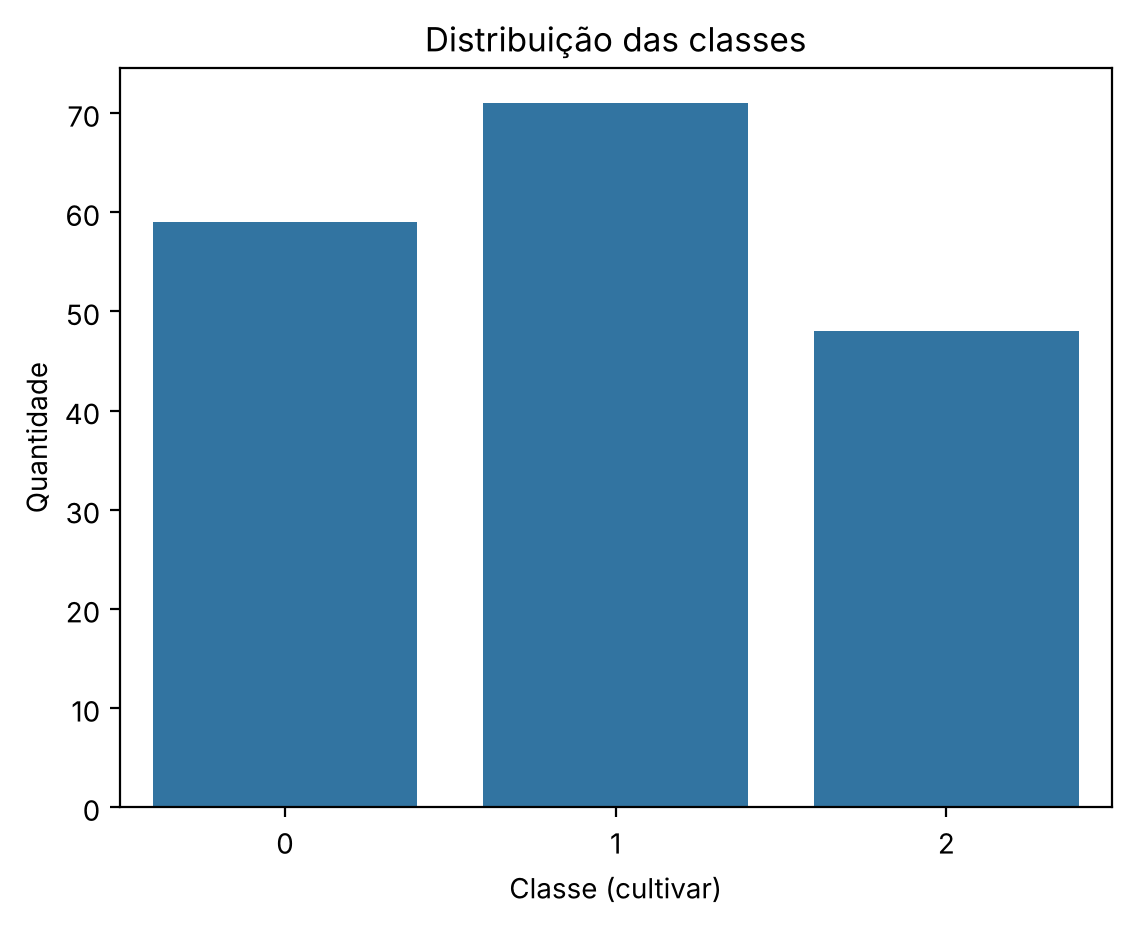

In [3]:
contagem = df["classe"].value_counts().sort_index()
print(contagem)

sns.countplot(x="classe", data=df)
plt.title("Distribuição das classes")
plt.xlabel("Classe (cultivar)")
plt.ylabel("Quantidade")
plt.show()

**Resposta:** classe 0 = 59, classe 1 = 71 e classe 2 = 48 amostras. As classes estão razoavelmente balanceadas, então a acurácia é uma métrica adequada.

## Questão 4 — Mostre as estatísticas descritivas. Os atributos estão na mesma escala?

In [4]:
df.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


**Resposta:** não. Por exemplo, `proline` varia de ~278 a ~1680, enquanto `hue` fica entre ~0,5 e ~1,7. Por isso modelos baseados em distância (como o KNN) precisam de **padronização** (`StandardScaler`).

## Questão 5 — Quais atributos têm maior correlação com a classe?

flavanoids                     -0.847498
od280/od315_of_diluted_wines   -0.788230
total_phenols                  -0.719163
proline                        -0.633717
hue                            -0.617369
Name: classe, dtype: float64


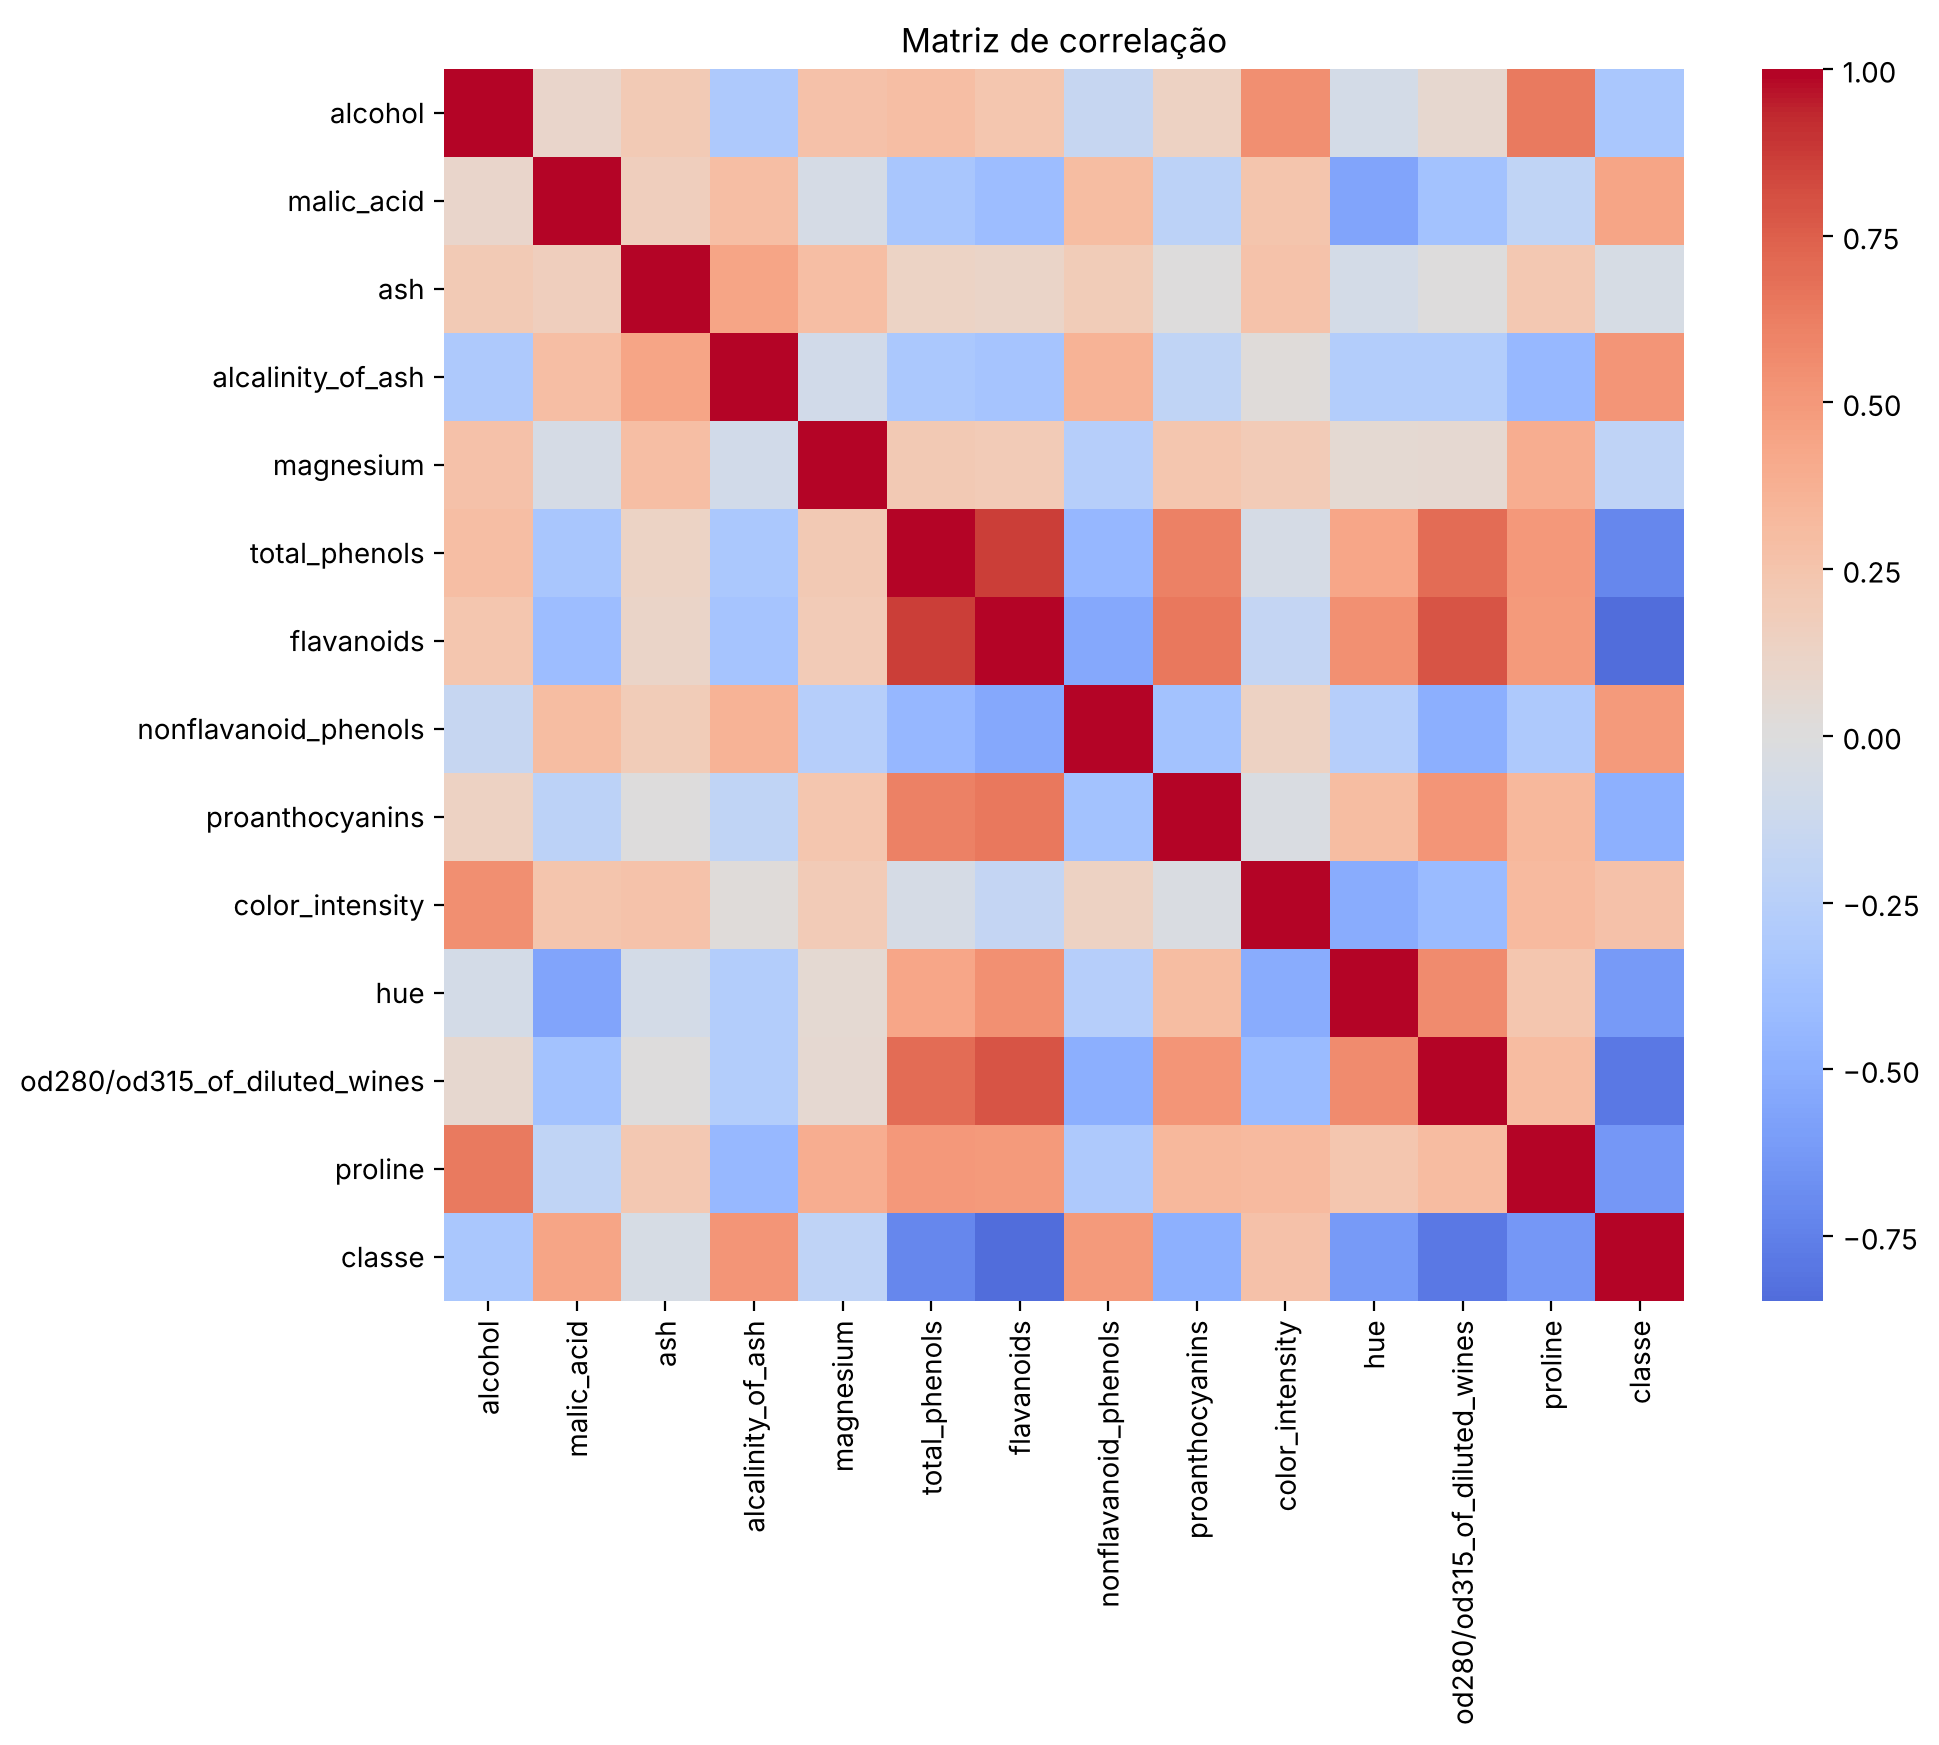

In [5]:
corr = df.corr()["classe"].drop("classe").sort_values(key=abs, ascending=False)
print(corr.head(5))

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Matriz de correlação")
plt.show()

**Resposta:** os atributos mais correlacionados (em valor absoluto) com a classe são `flavanoids`, `od280/od315_of_diluted_wines`, `total_phenols`, `hue` e `proline`.

## Questão 6 — Separe os dados em treino (70%) e teste (30%), mantendo a proporção das classes

In [6]:
X = df.drop(columns="classe")
y = df["classe"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("Treino:", X_train.shape, " Teste:", X_test.shape)

Treino: (124, 13)  Teste: (54, 13)


## Questão 7 — Treine três modelos e compare a acurácia no conjunto de teste

In [7]:
modelos = {
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}

resultados = {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    resultados[nome] = accuracy_score(y_test, pred)

pd.Series(resultados, name="Acurácia (teste)").sort_values(ascending=False).round(4)

Regressão Logística    0.9815
Árvore de Decisão      0.9630
KNN (k=5)              0.9444
Name: Acurácia (teste), dtype: float64

## Questão 8 — Valide os modelos com validação cruzada (5 folds)

In [8]:
cv = {}
for nome, modelo in modelos.items():
    scores = cross_val_score(modelo, X, y, cv=5)
    cv[nome] = (scores.mean(), scores.std())

pd.DataFrame(cv, index=["média", "desvio"]).T.round(4)

,média,desvio
KNN (k=5),0.9494,0.0379
Árvore de Decisão,0.8654,0.0440
Regressão Logística,0.9832,0.0137


**Resposta:** a Regressão Logística é a melhor (~98,3%, com o menor desvio), seguida pelo KNN (~94,9%). A Árvore de Decisão, que foi bem no teste (96,3%), cai para ~86,5% na validação cruzada: o resultado de uma única divisão treino/teste pode enganar, e a validação cruzada dá uma estimativa mais confiável.

## Questão 9 — Mostre a matriz de confusão e o relatório de classificação do melhor modelo

Melhor modelo: Regressão Logística
              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.95      0.98        21
     class_2       1.00      1.00      1.00        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



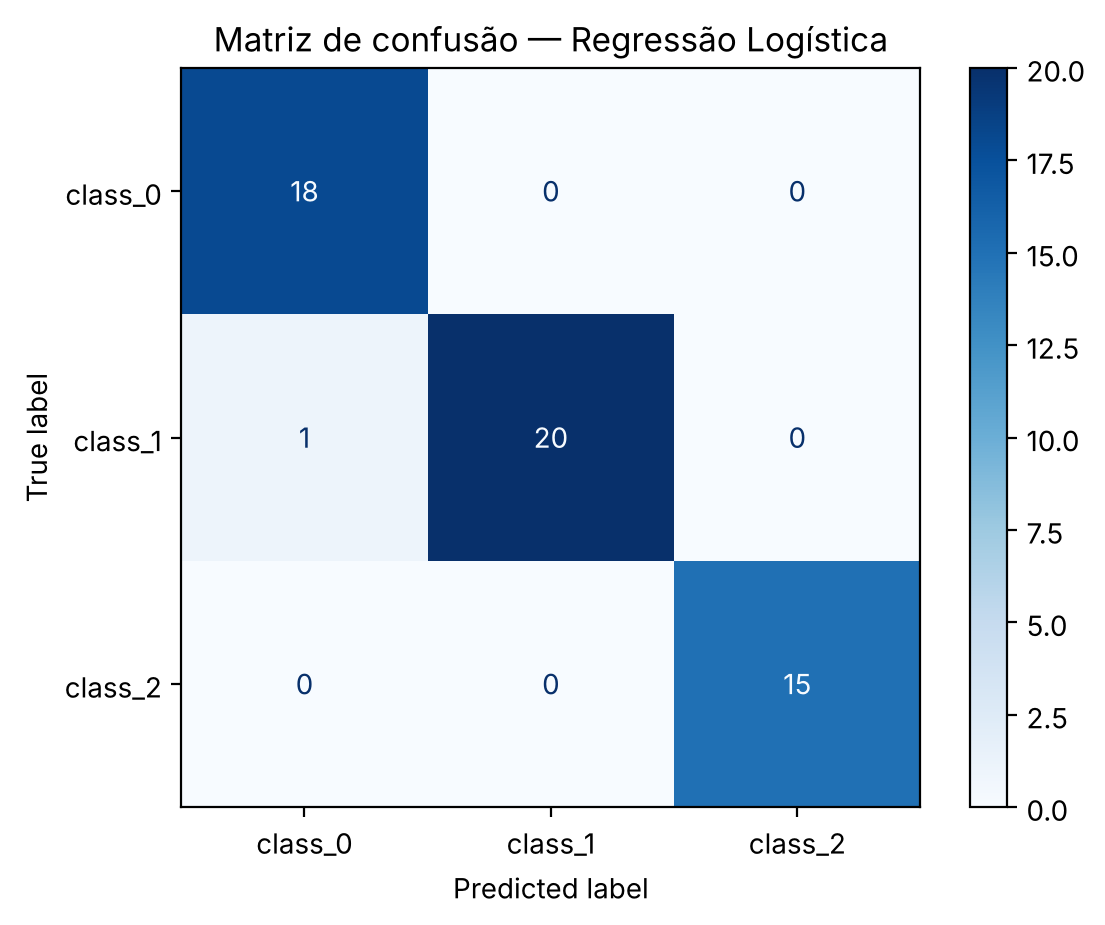

In [9]:
melhor_nome = max(cv, key=lambda k: cv[k][0])
melhor = modelos[melhor_nome]
pred = melhor.predict(X_test)

print("Melhor modelo:", melhor_nome)
print(classification_report(y_test, pred, target_names=wine.target_names))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=wine.target_names).plot(cmap="Blues")
plt.title(f"Matriz de confusão — {melhor_nome}")
plt.show()

## Questão 10 — Qual o efeito do valor de *k* no KNN?

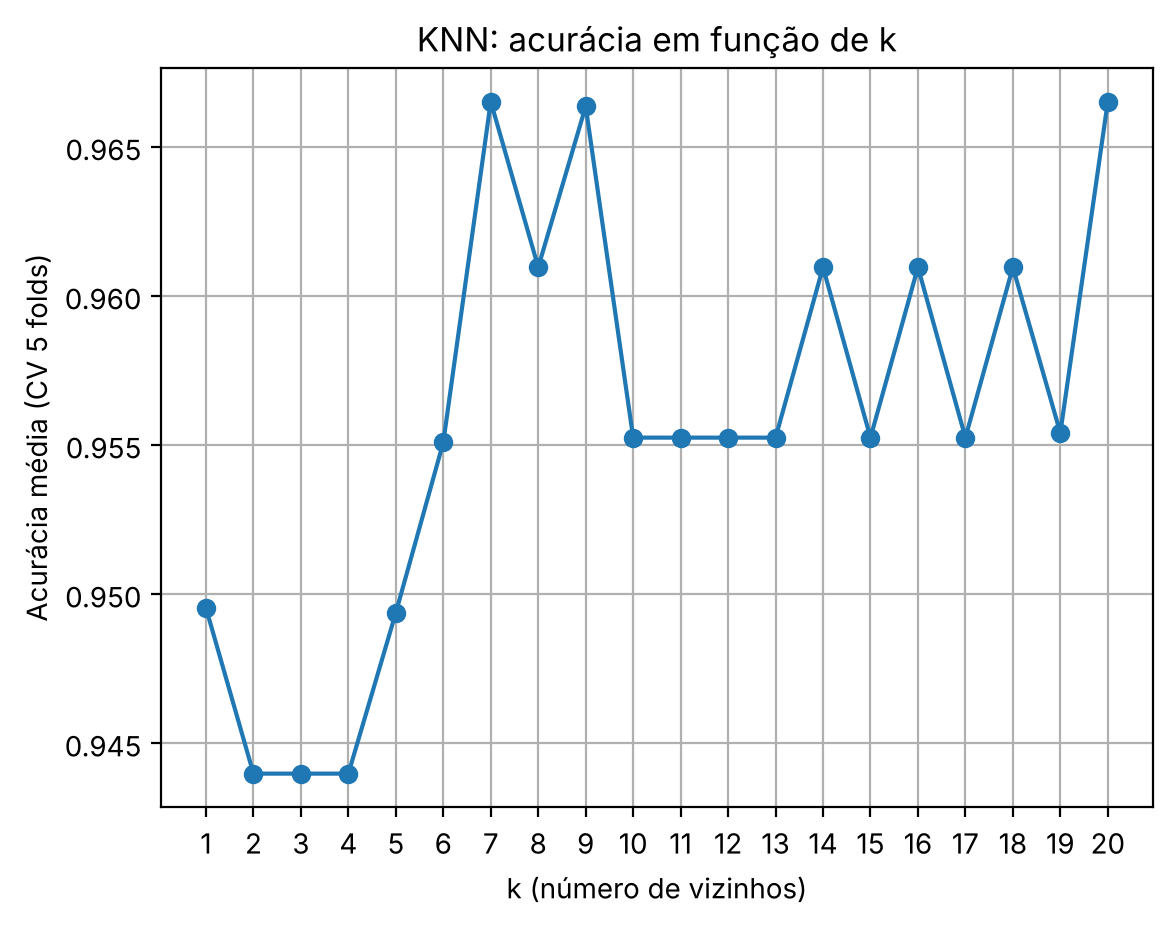

Melhor k: 7 com acurácia 0.9665


In [10]:
ks = range(1, 21)
acc = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), X, y, cv=5).mean() for k in ks]

plt.plot(ks, acc, marker="o")
plt.xlabel("k (número de vizinhos)")
plt.ylabel("Acurácia média (CV 5 folds)")
plt.title("KNN: acurácia em função de k")
plt.xticks(ks)
plt.grid(True)
plt.show()

print("Melhor k:", ks[int(np.argmax(acc))], "com acurácia", round(max(acc), 4))

## Conclusão

- O dataset Wine é pequeno, limpo (sem valores ausentes) e tem classes razoavelmente balanceadas.
- Os atributos estão em escalas muito diferentes, então **padronizar** faz muita diferença para o KNN e para a Regressão Logística.
- A **Regressão Logística** foi o melhor modelo (98,1% no teste e ~98,3% na validação cruzada). O KNN ficou em ~95% e a Árvore de Decisão, sem ajuste de hiperparâmetros, caiu para ~86,5% na validação cruzada.
- No teste, o melhor modelo errou apenas 1 das 54 amostras (um vinho da classe 1 classificado como classe 0).
- No KNN, valores muito pequenos de *k* tendem a *overfitting*; o melhor resultado foi com *k* = 7 (~96,7%).